# DATA-500: Homework Assignment 8

## Instructions

- This homework assignment is worth **62** points. 
- Please strive for clarity and organization.
- **AI Usage**:
   - AI use is strictly **prohibited** for conceptual exercises.
   - For applied (Python) exercises, you may only use AI for **debugging**. Do not use AI to generate answers.
- **Due Date: November 13, 2026, by 11:59 PM.**

# Exercise 1 

In this exercise, we will practice refactoring concepts in analytics/data science tasks. You are given a dataset about employees, including information such as their department, salary, and years of experience. Your task is to analyze the dataset and then refactor the code for readability and efficiency. 

### Exercise 1(a) (3 points)

Load `pandas` and create a data-frame called `df` using the below data dictionary:

```
data = {
    'EmployeeID': [101, 102, 103, 104, 105],
    'Department': ['Engineering', 'HR', 'Engineering', 'Sales', 'HR'],
    'Salary': [70000, 50000, 75000, 45000, 60000],
    'YearsExperience': [5, 3, 7, 2, 4]
}
```

In [1]:
import pandas as pd

data = {
    'EmployeeID': [101, 102, 103, 104, 105],
    'Department': ['Engineering', 'HR', 'Engineering', 'Sales', 'HR'],
    'Salary': [70000, 50000, 75000, 45000, 60000],
    'YearsExperience': [5, 3, 7, 2, 4]
}

df = pd.DataFrame(data)

df

,EmployeeID,Department,Salary,YearsExperience
0,101,Engineering,70000,5
1,102,HR,50000,3
2,103,Engineering,75000,7
3,104,Sales,45000,2
4,105,HR,60000,4


### Exercise 1(b) (4 points)

The below code snippet has three functions the perform the following:

- `calculate_average_salary` computes the average salary by department.
- `calculate_median_experience` computes the median years of experience for each department.
- `high_earners` identifies employees who earn above a certain salary threshold. 


```
# Calculate average salary by department
def calculate_average_salary(dataframe):
    avg_salary = dataframe.groupby('Department')['Salary'].mean()
    return avg_salary

# Calculate median years of experience by department
def calculate_median_experience(dataframe):
    median_exp = dataframe.groupby('Department')['YearsExperience'].median()
    return median_exp

# Identify employees with salaries above a certain threshold
def high_earners(dataframe, threshold):
    return dataframe[dataframe['Salary'] > threshold]

```

Make sure the above function are working as expected by applying them to the `df` data-frame.

In [5]:
def calculate_average_salary(dataframe):
    avg_salary = dataframe.groupby('Department')['Salary'].mean()
    return avg_salary

def calculate_median_experience(dataframe):
    median_exp = dataframe.groupby('Department')['YearsExperience'].median()
    return median_exp

def high_earners(dataframe, threshold):
    return dataframe[dataframe['Salary'] > threshold]

print(calculate_average_salary(df))

print(calculate_median_experience(df))

print(high_earners(df, 60000))

Department
Engineering    72500.0
HR             55000.0
Sales          45000.0
Name: Salary, dtype: float64
Department
Engineering    6.0
HR             3.5
Sales          2.0
Name: YearsExperience, dtype: float64
   EmployeeID   Department  Salary  YearsExperience
0         101  Engineering   70000                5
2         103  Engineering   75000                7


### Exercise 1(c) (6 points)

To improve code modularity, separate reusable components. Specifically:

- Add a helper function called `calculate_group_stat` to calculate group statistics (e.g., mean or median).
- Refactor the `calculate_average_salary` and `calculate_median_experience` functions to use the `calculate_group_stat` function.

Then, apply the refactored functions to the `df` data-frame

In [12]:
def calculate_group_stat(dataframe, column, stat):
    grouped = dataframe.groupby('Department')[column]

    if stat == 'mean':
        return grouped.mean()
    elif stat == 'median':
        return grouped.median()


def calculate_average_salary(dataframe):
    return calculate_group_stat(dataframe, 'Salary', 'mean')


def calculate_median_experience(dataframe):
    return calculate_group_stat(dataframe, 'YearsExperience', 'median')


print(calculate_average_salary(df))
print(calculate_median_experience(df))

Department
Engineering    72500.0
HR             55000.0
Sales          45000.0
Name: Salary, dtype: float64
Department
Engineering    6.0
HR             3.5
Sales          2.0
Name: YearsExperience, dtype: float64


### Exercise 1(d) (8 points)

To improve the readability of the functions, a description for each of the function. For example:

```
def high_earners(dataframe, threshold):
    """
    Identify employees with salaries above a certain threshold.

    Args:
        dataframe (pd.DataFrame): The DataFrame containing the data.
        threshold (int): The salary threshold to filter by.

    Returns:
        pd.DataFrame: A DataFrame of employees with salaries above the threshold.
    """
    return dataframe[dataframe['Salary'] > threshold]
```

Notice the function description.

In [13]:
def calculate_average_salary(dataframe):
    """
    Calculate the average salary for each department.

    Args:
        dataframe (pd.DataFrame): Employee data.

    Returns:
        pd.Series: Average salary for each department.
    """
    return calculate_group_stat(dataframe, 'Salary', 'mean')

### Exercise 1(e) (6 points)

Test the refactored code with test cases to ensure accuracy.

In [15]:
# Test average salary for Engineering
average_salary = calculate_average_salary(df)

assert average_salary['Engineering'] == 72500

print("Average salary test passed!")

Average salary test passed!


# Exercise 2

In this exercise, we will practice `polars` operations. Consider the `Electronic_sales_Sep2023-Sep2024.csv` data file. This dataset contains sales transaction records for an electronics company over a one-year period, spanning from September 2023 to September 2024. It includes detailed information about customer demographics, product types, and purchase behaviors. This is a brief description of each columns in the data file.

- `Customer ID`: Unique identifier for each customer.
- `Age`: Age of the customer (numeric)
- `Gender`: Gender of the customer (Male or Female)
- `Loyalty Member`: (Yes/No) (Values change by time, so pay attention to who cancelled and who signed up)
- `Product Type`: Type of electronic product sold (e.g., Smartphone, Laptop, Tablet)
- `SKU`: a unique code for each product.
- `Rating`: Customer rating of the product (1-5 stars) (Should have no Null Ratings)
- `Order Status`: Status of the order (Completed, Cancelled)
- `Payment Method`: Method used for payment (e.g., Cash, Credit Card, Paypal)
- `Total Price`: Total price of the transaction (numeric)
- `Unit Price`: Price per unit of the product (numeric)
- `Quantity`: Number of units purchased (numeric)
- `Purchase Date`: Date of the purchase (format: YYYY-MM-DD)
- `Shipping Type`: Type of shipping chosen (e.g., Standard, Overnight, Express)
- `Add-ons Purchased`: List of any additional items purchased (e.g., Accessories, Extended Warranty)
- `Add-on Total`: Total price of add-ons purchased (numeric)


### Exercise 2(a) (2 points)

Load `polars`, `matplotlib.pyplot` and `seaborn`.

In [16]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

### Exercise 2(b) (2 points)

Read the `Electronic_sales_Sep2023-Sep2024.csv` data file and create a data frame called `df`. Report the shape of `df`.

In [18]:
df = pl.read_csv("Electronic_sales_Sep2023-Sep2024.csv")

print(df.shape)

(20000, 16)


### Exercise 2(c) (3 points)

Report the number of unique `Customer ID`.

In [19]:
unique_customers = df["Customer ID"].n_unique()

print("Number of unique customers:", unique_customers)

Number of unique customers: 12136


### Exercise 2(d) (3 points)

Create a column called `Total_Spending`, which is the sum of `Total Price` and `Add-on Total`.

In [20]:
df = df.with_columns(
    (pl.col("Total Price") + pl.col("Add-on Total")).alias("Total_Spending")
)

df.select(["Total Price", "Add-on Total", "Total_Spending"]).head()

Total Price,Add-on Total,Total_Spending
f64,f64,f64
5538.33,40.21,5578.54
741.09,26.09,767.18
1855.84,0.0,1855.84
3164.76,60.16,3224.92
41.5,35.56,77.06


### Exercise 2(e) (3 points)

Compute the average `Total_Spending` by `Customer ID`. Report the `Customer ID`s with the smallest and largest average `Total_Spending`.

In [22]:
avg_spending = df.group_by("Customer ID").agg(
    pl.col("Total_Spending").mean().alias("Average_Spending")
)

avg_spending.head()

print("Smallest average spending:")
print(avg_spending.sort("Average_Spending").head(1))

print("Largest average spending:")
print(avg_spending.sort("Average_Spending", descending=True).head(1))

Smallest average spending:
shape: (1, 2)
┌─────────────┬──────────────────┐
│ Customer ID ┆ Average_Spending │
│ ---         ┆ ---              │
│ i64         ┆ f64              │
╞═════════════╪══════════════════╡
│ 8063        ┆ 20.75            │
└─────────────┴──────────────────┘
Largest average spending:
shape: (1, 2)
┌─────────────┬──────────────────┐
│ Customer ID ┆ Average_Spending │
│ ---         ┆ ---              │
│ i64         ┆ f64              │
╞═════════════╪══════════════════╡
│ 12611       ┆ 11655.12         │
└─────────────┴──────────────────┘


### Exercise 2(f) (5 points)

Report the most popular `Product Type` among `Male` and `Female`.

In [23]:
product_counts = (
    df.group_by(["Gender", "Product Type"])
    .agg(pl.len().alias("Count"))
    .sort(["Gender", "Count"], descending=[False, True])
)

most_popular = product_counts.group_by("Gender").first()

print(most_popular)

shape: (3, 3)
┌────────┬──────────────┬───────┐
│ Gender ┆ Product Type ┆ Count │
│ ---    ┆ ---          ┆ ---   │
│ str    ┆ str          ┆ u32   │
╞════════╪══════════════╪═══════╡
│ #N/A   ┆ Laptop       ┆ 1     │
│ Female ┆ Smartphone   ┆ 2980  │
│ Male   ┆ Smartphone   ┆ 2998  │
└────────┴──────────────┴───────┘


### Exercise 2(g) (4 points)

Do loyal customers spend more? 

In [24]:
loyalty_spending = (
    df.group_by("Loyalty Member")
    .agg(
        pl.col("Total_Spending").mean().alias("Average_Spending")
    )
)

print(loyalty_spending)

shape: (2, 2)
┌────────────────┬──────────────────┐
│ Loyalty Member ┆ Average_Spending │
│ ---            ┆ ---              │
│ str            ┆ f64              │
╞════════════════╪══════════════════╡
│ Yes            ┆ 3199.751976      │
│ No             ┆ 3254.202114      │
└────────────────┴──────────────────┘


Based on the results, customers without a loyalty membership spent slightly more on average than loyalty members. Nonmembers spent approximately $3,254.20 per transaction, compared to $3,199.75 for loyalty members.

### Exercise 2(h) (5 points)

Does age play a role on the total amount of the transaction?

shape: (1, 1)
┌──────────┐
│ Age      │
│ ---      │
│ f64      │
╞══════════╡
│ 0.002969 │
└──────────┘


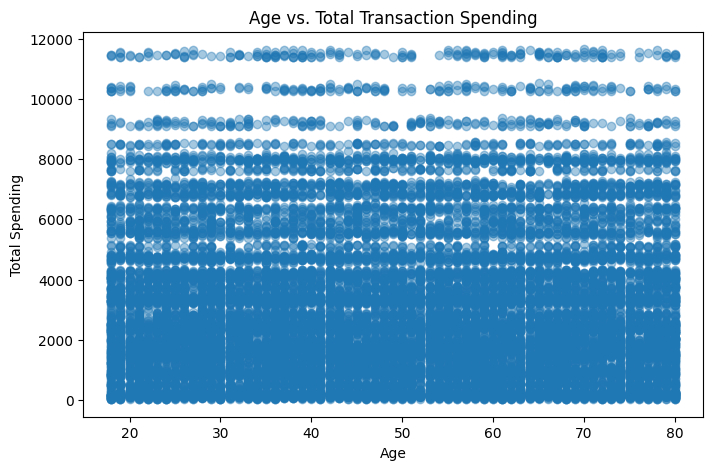

In [25]:
# Calculate correlation
correlation = df.select(
    pl.corr("Age", "Total_Spending")
)

print(correlation)

# Create scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Age"].to_numpy(),
    df["Total_Spending"].to_numpy(),
    alpha=0.4
)

plt.xlabel("Age")
plt.ylabel("Total Spending")
plt.title("Age vs. Total Transaction Spending")
plt.show()

based on the correlation and scatter plot, age does not appear to have a strong relationship with total transaction spending. The correlation is approximatley 0.003, which is very close to zero. This suggests that customners of different ages have similar spending patterns overall.

# Exercise 3

In this exercise, we will review the design and refactoring concepts from Chapter 8. Answer in your own words (no AI).


### Exercise 3(a) (3 points)

Consider the following function:

```
THRESHOLD = 60000

def flag_high_earners(dataframe):
    dataframe['HighEarner'] = dataframe['Salary'] > THRESHOLD
    return dataframe
```

A colleague changes `THRESHOLD` elsewhere in the module, and the results of `flag_high_earners` silently change. Which statement best describes the design problem and its fix?

A. The function has low cohesion; it should be split into two functions, one for each column it touches.

B. The function is tightly coupled to a hidden module-level value that does not appear in its signature; pass `threshold` as an argument (dependency injection) instead.

C. The function lacks a docstring; adding a description of the `THRESHOLD` value removes the problem.

D. The function is a code smell because it is short; it should be inlined into the calling code.


b

### Exercise 3(b) (5 points)

A teammate asks you to restructure a long, untested notebook function so that it is easier to read. They suggest rewriting it from scratch in one large step, and also fixing a few bugs they noticed along the way.

1. Using the definition of refactoring, explain why this plan is risky. (2 points)
2. Describe the steps you would take instead, including what you would do first since there are no tests. (3 points)


1. Refactoring is defined as restructuring existing code without changing its external behavior. Rewriting from scratch in one large step violates this because it changes behavior (and mixes in bug fixes), so there's no way to verify the restructured code is equivalent to the original. A big-bang rewrite also makes it impossible to isolate where errors are introduced, and combining refactoring with bug fixes conflates two different activities—you can no longer tell whether a change in output is due to a bug fix or an accidental behavior change.

2.  Since there are no tests, the first step is to write characterization tests that capture the current behavior of the function (even the buggy behavior), so you have a safety net to detect unintended changes. Then: (a) separate the concerns—do the refactoring first and fix bugs in a separate later step; (b) refactor in small, incremental steps, running the tests after each change and committing when green; (c) if the function is too large to test, extract and test smaller pieces as you go; (d) only after the refactor is complete and behavior is verified unchanged, address the bugs (updating tests to reflect the intended correct behavior).